Data loading


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', '{:.2f}'.format)
sns.set_theme(style='darkgrid', palette='husl')
plt.rcParams['figure.dpi']=120

df = pd.read_csv('/content/WA_Fn-UseC_-Telco-Customer-Churn.csv')

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.shape

(7043, 21)

In [3]:
df.dtypes

,0
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object


In [4]:
#Total charges is stored as object instead of float
print("Numeric columns summary:")
df.describe().T

Numeric columns summary:


,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.00,0.16,0.37,0.00,0.00,0.00,0.00,1.00
tenure,7043.00,32.37,24.56,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.00,64.76,30.09,18.25,35.50,70.35,89.85,118.75


In [5]:
missing= df.isnull().sum()
(missing/len(df) * 100).round(2)


,0
customerID,0.00
gender,0.00
SeniorCitizen,0.00
Partner,0.00
Dependents,0.00
tenure,0.00
PhoneService,0.00
MultipleLines,0.00
InternetService,0.00
OnlineSecurity,0.00


In [6]:
churn_count = df['Churn'].value_counts()
df['Churn'].value_counts(normalize=True) *100

,proportion
Churn,
No,73.46
Yes,26.54


In [7]:
print(f"Imbalance ratio : 1:{churn_count['No']/churn_count['Yes']:.1f}" )

Imbalance ratio : 1:2.8


Data-cleaning

In [8]:

df.drop(columns=['customerID'],inplace=True)
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [9]:
df.shape

(7043, 20)

In [10]:
df['TotalCharges'] = df['TotalCharges'].replace(' ', np.nan)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'])
df['TotalCharges'].isnull().sum()

np.int64(11)

In [11]:
# 11 missing values found in TotalCharges coloumn
df[df['TotalCharges'].isnull()]

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


In [12]:
missing_rows = df[df['TotalCharges'].isnull()]

In [13]:
(missing_rows['tenure'] ==0).all()

np.True_

In [14]:
# All the missing values in TotalCharges are with tenure 0, hence the charges should also be 0
df['TotalCharges'].fillna(0.0, inplace=True)

In [15]:
df['Churn'] = df['Churn'].map({'Yes' : 1, 'No' : 0})
df['Churn'].unique()

array([0, 1])

In [16]:
#Encoding
binary_cols = ['Partner', 'Dependents', 'PhoneService',
               'PaperlessBilling']

for col in binary_cols:
    df[col] = df[col].map({'Yes': 1, 'No': 0})

In [17]:
df[binary_cols]

,Partner,Dependents,PhoneService,PaperlessBilling
0,1,0,0,1
1,0,0,1,0
2,0,0,1,1
3,0,0,0,0
4,0,0,1,1
...,...,...,...,...
7038,1,1,1,1
7039,1,1,1,1
7040,1,1,0,1
7041,1,0,1,1


In [18]:
df['gender'] = df['gender'].map({'Male': 1, 'Female': 0})
df['gender']

,gender
0,0
1,1
2,1
3,1
4,0
...,...
7038,1
7039,0
7040,0
7041,1


In [19]:
#Duplicate check
dupes = df.duplicated().sum()
print(dupes)

22


In [20]:
df.shape

(7043, 20)

In [21]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,1,Electronic check,29.85,29.85,0
1,1,0,0,0,34,1,No,DSL,Yes,No,Yes,No,No,No,One year,0,Mailed check,56.95,1889.50,0
2,1,0,0,0,2,1,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,1,Mailed check,53.85,108.15,1
3,1,0,0,0,45,0,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,0,0,0,0,2,1,No,Fiber optic,No,No,No,No,No,No,Month-to-month,1,Electronic check,70.70,151.65,1


In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   int64  
 1   SeniorCitizen     7043 non-null   int64  
 2   Partner           7043 non-null   int64  
 3   Dependents        7043 non-null   int64  
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   int64  
 6   MultipleLines     7043 non-null   object 
 7   InternetService   7043 non-null   object 
 8   OnlineSecurity    7043 non-null   object 
 9   OnlineBackup      7043 non-null   object 
 10  DeviceProtection  7043 non-null   object 
 11  TechSupport       7043 non-null   object 
 12  StreamingTV       7043 non-null   object 
 13  StreamingMovies   7043 non-null   object 
 14  Contract          7043 non-null   object 
 15  PaperlessBilling  7043 non-null   int64  
 16  PaymentMethod     7043 non-null   object 


In [23]:
cat_cols = df.select_dtypes(include='object').columns.tolist()
cat_cols

['MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaymentMethod']

In [24]:
for col in cat_cols:
    print(f"  {col} → {df[col].nunique()} unique values: {df[col].unique()[:4].tolist()}")

  MultipleLines → 3 unique values: ['No phone service', 'No', 'Yes']
  InternetService → 3 unique values: ['DSL', 'Fiber optic', 'No']
  OnlineSecurity → 3 unique values: ['No', 'Yes', 'No internet service']
  OnlineBackup → 3 unique values: ['Yes', 'No', 'No internet service']
  DeviceProtection → 3 unique values: ['No', 'Yes', 'No internet service']
  TechSupport → 3 unique values: ['No', 'Yes', 'No internet service']
  StreamingTV → 3 unique values: ['No', 'Yes', 'No internet service']
  StreamingMovies → 3 unique values: ['No', 'Yes', 'No internet service']
  Contract → 3 unique values: ['Month-to-month', 'One year', 'Two year']
  PaymentMethod → 4 unique values: ['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']


In [25]:
#EDA
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,1,Electronic check,29.85,29.85,0
1,1,0,0,0,34,1,No,DSL,Yes,No,Yes,No,No,No,One year,0,Mailed check,56.95,1889.50,0
2,1,0,0,0,2,1,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,1,Mailed check,53.85,108.15,1
3,1,0,0,0,45,0,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,0,0,0,0,2,1,No,Fiber optic,No,No,No,No,No,No,Month-to-month,1,Electronic check,70.70,151.65,1


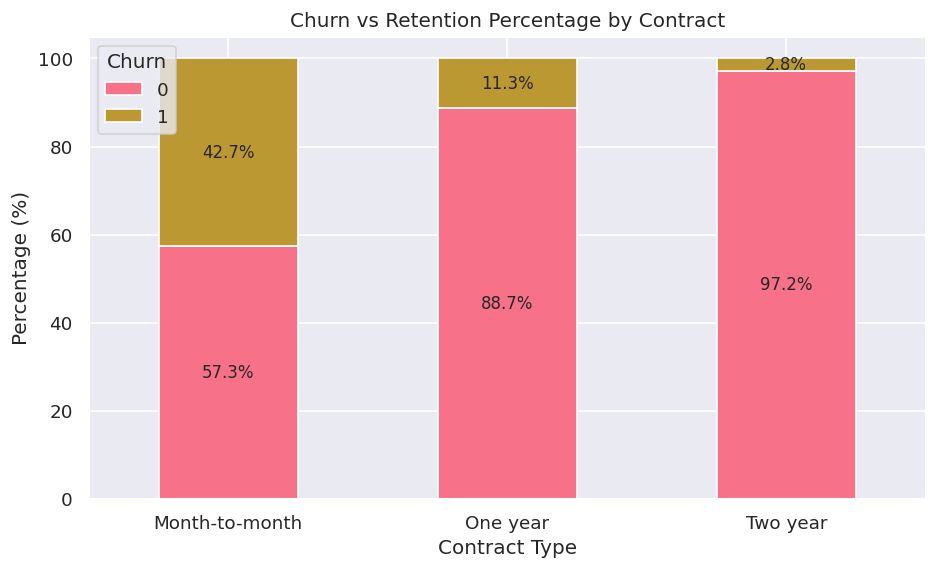

In [26]:
contract_churn = pd.crosstab(
    df["Contract"],
    df["Churn"],
    normalize="index"
) * 100

ax = contract_churn.plot(kind="bar", stacked=True, figsize=(9, 5))

for container in ax.containers:
    labels = [
        f"{bar.get_height():.1f}%" if bar.get_height() > 0 else ""
        for bar in container
    ]
    ax.bar_label(container, labels=labels, label_type="center", fontsize=10)
plt.title("Churn vs Retention Percentage by Contract")
plt.xlabel("Contract Type")
plt.ylabel("Percentage (%)")
plt.xticks(rotation=0)
plt.legend(title="Churn")
plt.show()

In [27]:
#Month-to-month has highest churn rate, then one year and then two year customers have the lowest churn rate
#longer the contract, less the churn rate

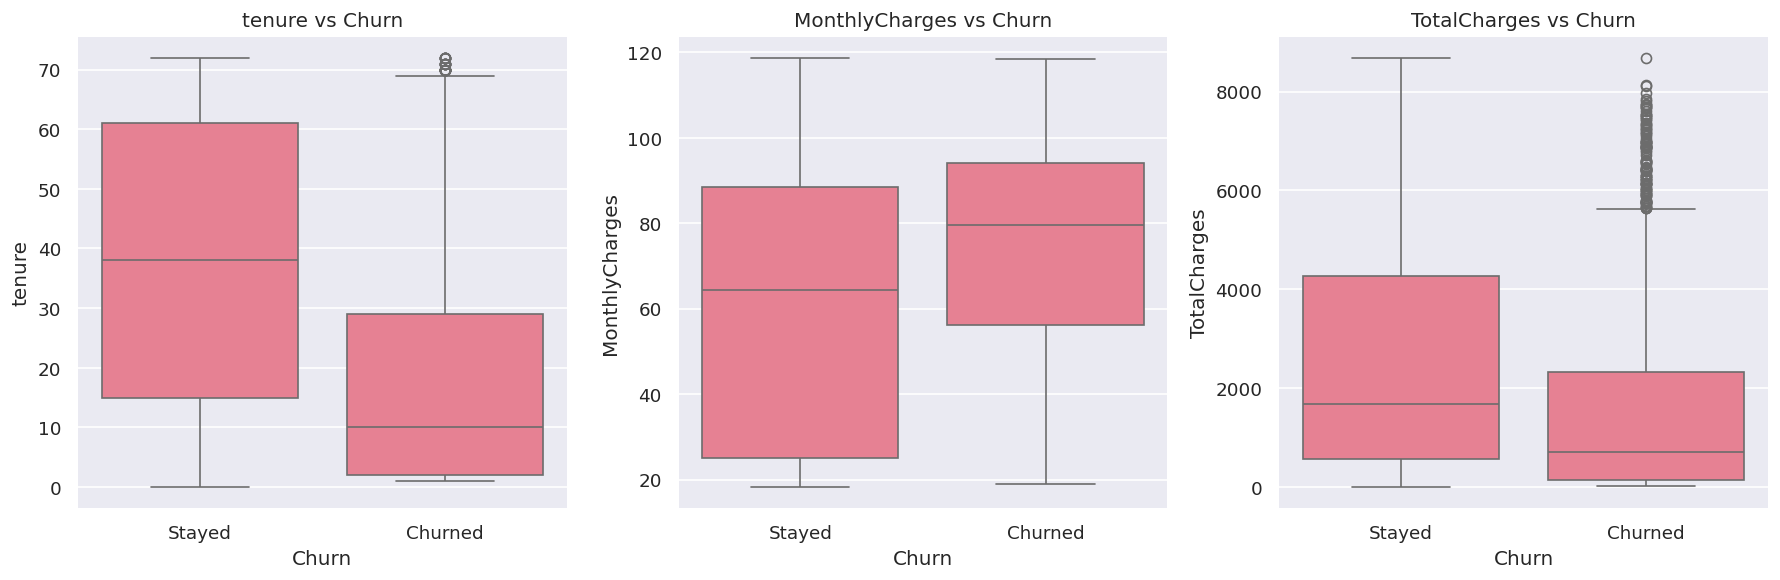

In [28]:
numeric_features = ['tenure', 'MonthlyCharges', 'TotalCharges']

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax, feat in zip(axes, numeric_features):
    sns.boxplot(data=df, x='Churn', y=feat, ax=ax)
    ax.set_title(f'{feat} vs Churn')
    ax.set_xticks([0, 1], ['Stayed', 'Churned'])

plt.tight_layout()
plt.show()

In [29]:
#Tenure vs Churn - Churned customers have much lower tenure vs stayed. New customers churn most.
#MonthlyCharges vs Churn - Churned customers pay higher monthly charges vs stayed
#TotalCharges vs Churn - Churned customers have lower total charges — confirming they're newer customers who leave before accumulating high total spend.

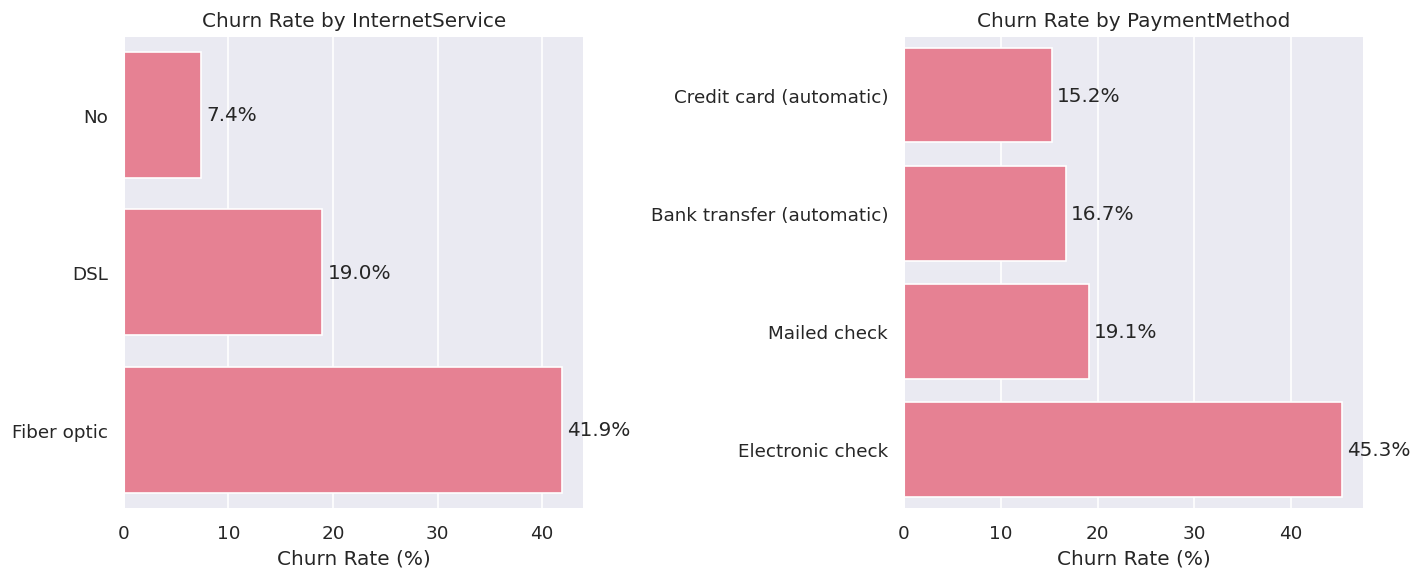

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, col in zip(axes, ['InternetService', 'PaymentMethod']):
    rates = (df.groupby(col)['Churn'].mean() * 100).sort_values()

    sns.barplot(x=rates.values, y=rates.index, ax=ax)

    ax.set_title(f'Churn Rate by {col}')
    ax.set_xlabel('Churn Rate (%)')
    ax.set_ylabel('')

    for i, val in enumerate(rates.values):
        ax.text(val + 0.5, i, f'{val:.1f}%', va='center')

plt.tight_layout()
plt.show()

In [31]:
#Customers with fiber optics internet service have the highest churn rate
#Customers with no internet service have the lowest churn rate
#Customers with automatic payment methods have lower churn rates whereas electronic check has the highest churn

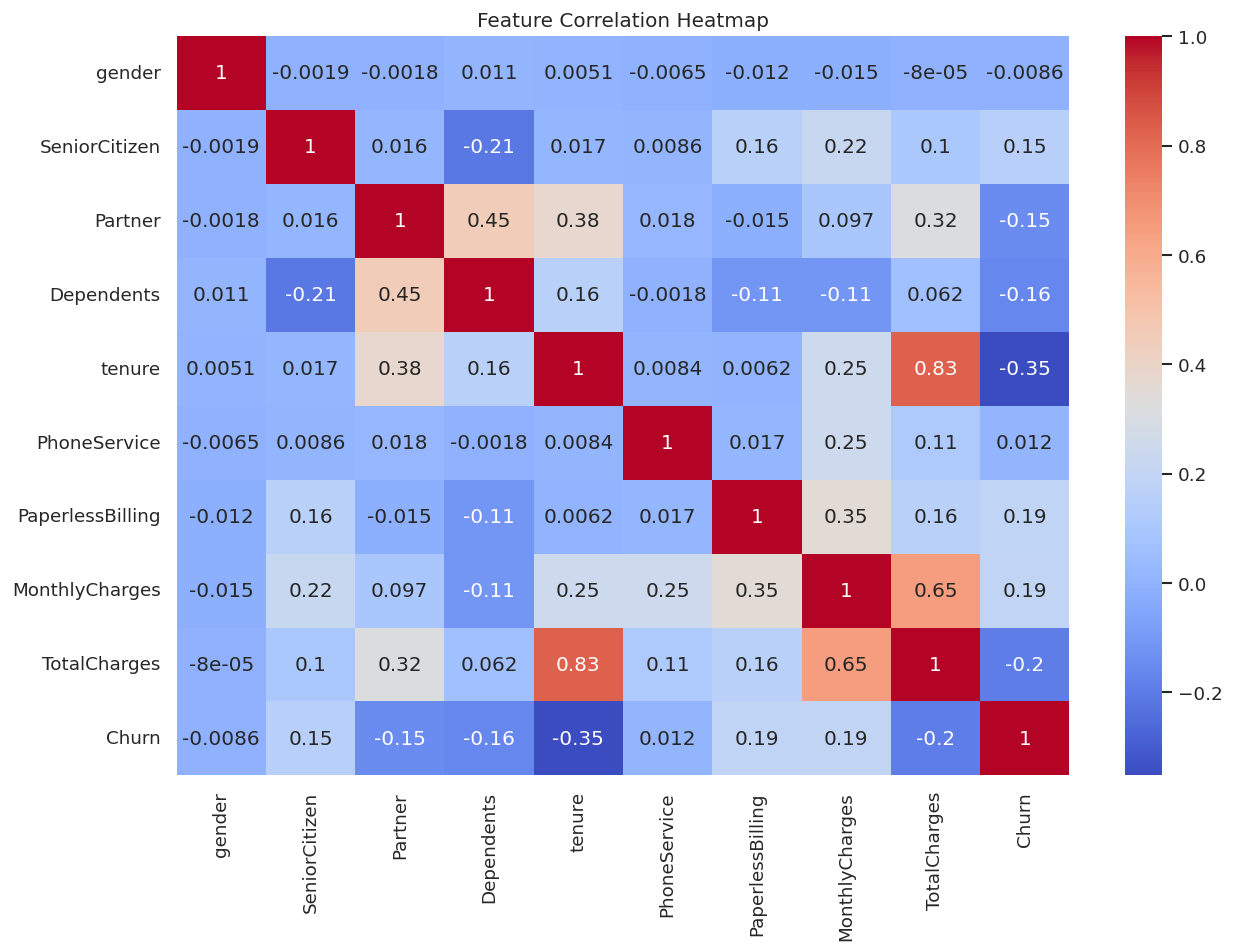

In [32]:
plt.figure(figsize=(12, 8))
numeric_df = df.select_dtypes(include='number')
corr = numeric_df.corr()
sns.heatmap(corr, annot=True, cmap='coolwarm')
plt.title('Feature Correlation Heatmap')
plt.show()

In [33]:
 corr['Churn'].drop('Churn').sort_values(key=abs,ascending=False)

,Churn
tenure,-0.35
TotalCharges,-0.20
MonthlyCharges,0.19
PaperlessBilling,0.19
Dependents,-0.16
SeniorCitizen,0.15
Partner,-0.15
PhoneService,0.01
gender,-0.01


In [34]:
#tenure - Negative correlation (~−0.35), longer tenure = less churn. Most important numeric predictor.
#MonthlyCharges - Positive correlation (~+0.19),higher bills = more churn tendency.
#TotalCharges - Negative correlation, driven by tenure (long-tenure customers accumulate high total charges and churn less).

In [35]:
insights = [
    ("Contract type",
     "Month-to-month customers churn at 42% vs 3% for 2-year contracts",
     "Push customers toward annual contracts with discounts"),

    ("Tenure",
     "Churned customers avg 18 months tenure vs 37 for stayed",
     "First 12 months is highest risk — target early with loyalty programmes"),

    ("Monthly Charges",
     "Churned customers pay ~$13 more per month on average",
     "High-bill + new customer = highest churn risk segment"),

    ("Internet Service",
     "Fiber optic users churn at 42% — highest of any service",
     "Review fiber pricing; consider loyalty incentives for fiber users"),

    ("Payment Method",
     "Electronic check users churn most — manual payment = low engagement",
     "Incentivise auto-pay setup with first-month discount"),
]

print("━"*70)
print(f"{'FEATURE':20} {'FINDING':30} ")
print("━"*70)
for feat, finding, action in insights:
    print(f"  {feat:18} {finding:50}")
    print(f"  {'Action':18} # {action}")
    print()
print("━"*70)

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
FEATURE              FINDING                        
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Contract type      Month-to-month customers churn at 42% vs 3% for 2-year contracts
  Action             # Push customers toward annual contracts with discounts

  Tenure             Churned customers avg 18 months tenure vs 37 for stayed
  Action             # First 12 months is highest risk — target early with loyalty programmes

  Monthly Charges    Churned customers pay ~$13 more per month on average
  Action             # High-bill + new customer = highest churn risk segment

  Internet Service   Fiber optic users churn at 42% — highest of any service
  Action             # Review fiber pricing; consider loyalty incentives for fiber users

  Payment Method     Electronic check users churn most — manual payment = low engagement
  Action             # Incentivise auto-pay setup with first-

In [36]:
#Creating new features

# tenure group (first 12 monthhs = highest churn risk)
df['tenure_group'] = pd.cut(df['tenure'],
                            bins =[0,12,24,48,72],
                            labels=['0-12m', '12-24m', '24-48m', '48-72m']
                            )
# charges per month ratio (High-bill + new customer = highest churn risk segment)
df['charges_ratio']= np.where(df['TotalCharges'] > 0,
                              df['MonthlyCharges'] / df['TotalCharges'],
                              1.0
                              )
# number of services (ustomers with more services are less likely to churn)
service_cols = ['PhoneService', 'PaperlessBilling',
                'Partner', 'Dependents']
df['num_services'] = df[service_cols].sum(axis=1)

# new customers with month-to-month contract are high risk category
df['is_high_risk'] = ((df['Contract'] == 'Month-to-month') &(df['tenure'] <= 12)).astype(int)

# Normalised spend: how much does this customer pay vs the average?
mean_charge = df['MonthlyCharges'].mean()
df['monthly_charge_above_avg'] = (
    df['MonthlyCharges'] - mean_charge
)

new_feats = ['tenure_group', 'charges_ratio',
             'num_services', 'is_high_risk',
             'monthly_charge_above_avg']

df[new_feats].head(8)

,tenure_group,charges_ratio,num_services,is_high_risk,monthly_charge_above_avg
0,0-12m,1.00,2,1,-34.91
1,24-48m,0.03,1,0,-7.81
2,0-12m,0.50,2,1,-10.91
3,24-48m,0.02,0,0,-22.46
4,0-12m,0.47,2,1,5.94
5,0-12m,0.12,2,1,34.89
6,12-24m,0.05,3,0,24.34
7,0-12m,0.10,0,1,-35.01


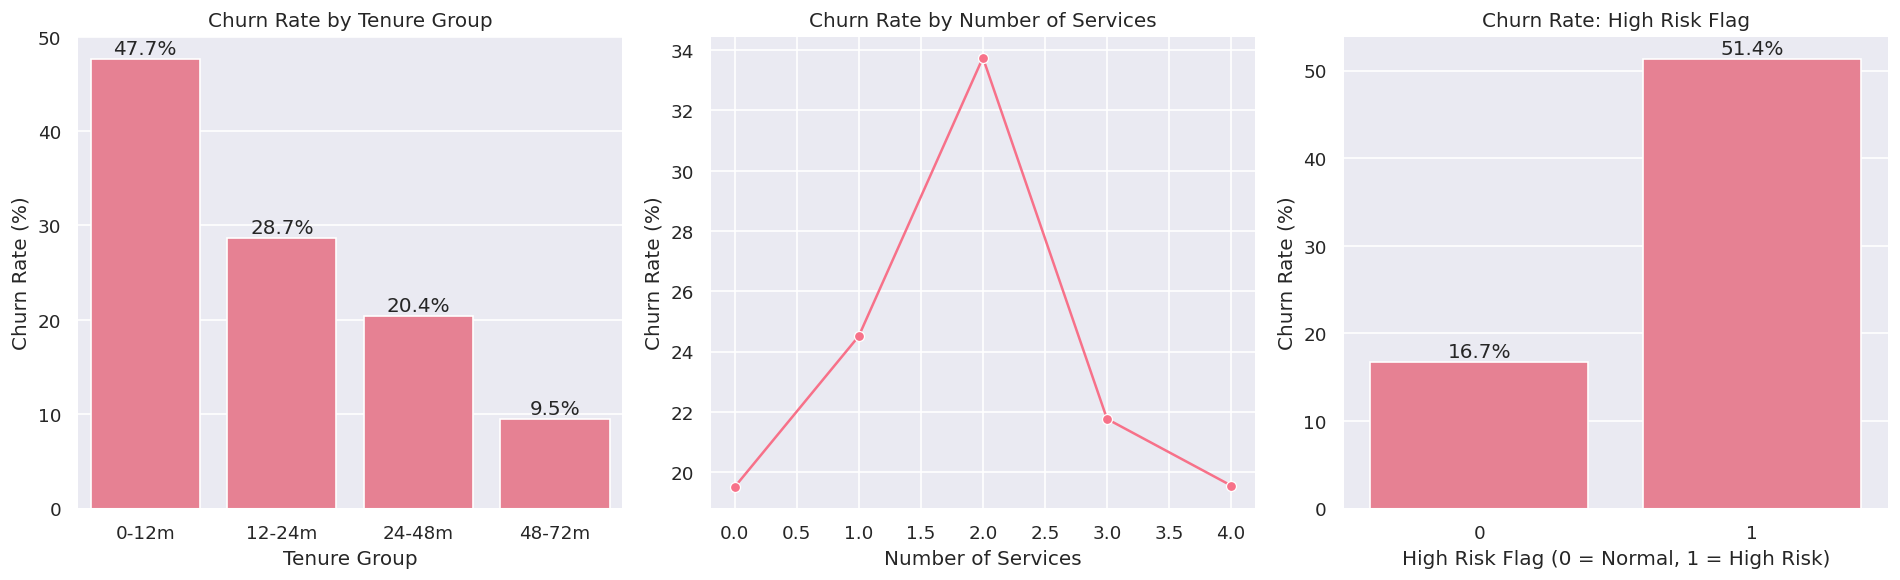

In [37]:

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# 1. Churn rate by tenure group
tg_churn = df.groupby(
    'tenure_group', observed=True
)['Churn'].mean().mul(100)

sns.barplot(x=tg_churn.index.astype(str), y=tg_churn.values, ax=axes[0])
axes[0].set_title('Churn Rate by Tenure Group')
axes[0].set_xlabel('Tenure Group')
axes[0].set_ylabel('Churn Rate (%)')

for i, v in enumerate(tg_churn.values):
    axes[0].text(i, v + 0.5, f'{v:.1f}%', ha='center')

# 2. Churn rate by number of services
ns_churn = df.groupby('num_services')['Churn'].mean().mul(100)

sns.lineplot(x=ns_churn.index, y=ns_churn.values,
             marker='o', ax=axes[1])
axes[1].set_title('Churn Rate by Number of Services')
axes[1].set_xlabel('Number of Services')
axes[1].set_ylabel('Churn Rate (%)')

# 3. Churn rate by high-risk flag
hr_churn = df.groupby('is_high_risk')['Churn'].mean().mul(100)

sns.barplot(x=hr_churn.index, y=hr_churn.values, ax=axes[2])
axes[2].set_title('Churn Rate: High Risk Flag')
axes[2].set_xlabel('High Risk Flag (0 = Normal, 1 = High Risk)')
axes[2].set_ylabel('Churn Rate (%)')

for i, v in enumerate(hr_churn.values):
    axes[2].text(i, v + 0.5, f'{v:.1f}%', ha='center')

plt.tight_layout()
plt.show()

In [38]:
#seperating features(x) and target(y)

from sklearn.model_selection import train_test_split

X= df.drop(columns=['Churn'])
y= df['Churn']


cat_cols = X.select_dtypes(include=['object', 'category']).columns.tolist()
num_cols = X.select_dtypes(include = ['int64', 'float64']).columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(X,y,test_size = 0.2, random_state=42, stratify=y)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((5634, 24), (1409, 24), (5634,), (1409,))

In [39]:
cat_cols

['MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaymentMethod',
 'tenure_group']

In [40]:
num_cols

['gender',
 'SeniorCitizen',
 'Partner',
 'Dependents',
 'tenure',
 'PhoneService',
 'PaperlessBilling',
 'MonthlyCharges',
 'TotalCharges',
 'charges_ratio',
 'num_services',
 'is_high_risk',
 'monthly_charge_above_avg']

In [41]:
!pip install imbalanced-learn --quiet

In [42]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (classification_report,
                              confusion_matrix,
                              roc_auc_score,
                              f1_score,
                              ConfusionMatrixDisplay)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

In [43]:
#numeric pipeline
numeric_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler())
])

#categorical pipeline
categorical_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(
        handle_unknown='ignore',
        sparse_output=False
    ))
])


#column transformer
preprocessor = ColumnTransformer([
    ('num', numeric_pipeline,    num_cols),
    ('cat', categorical_pipeline, cat_cols)
], remainder='passthrough')

In [44]:
pipelines = {
    'Logistic Regression': ImbPipeline([
        ('preprocessor', preprocessor),
        ('smote',        SMOTE(random_state=42)),
        ('classifier',   LogisticRegression(
            max_iter=1000,
            class_weight='balanced',
            random_state=42
        ))
    ]),

    'Random Forest': ImbPipeline([
        ('preprocessor', preprocessor),
        ('smote',        SMOTE(random_state=42)),
        ('classifier',   RandomForestClassifier(
            n_estimators=200,
            class_weight='balanced',
            random_state=42,
            n_jobs=-1
        ))
    ]),
}

In [45]:
# ── STRATIFIED K-FOLD CROSS VALIDATION ───────────────
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_results = {}

for name, pipeline in pipelines.items():
    scores = cross_validate(
        pipeline, X_train, y_train,
        cv=cv,
        scoring=['f1', 'roc_auc', 'precision', 'recall'],
        return_train_score=False,
        n_jobs=-1
    )
    cv_results[name] = scores

    print(f"{'━'*45}")
    print(f"  {name}")
    print(f"{'━'*45}")
    print(f"  F1 Score  : {scores['test_f1'].mean():.3f} ± {scores['test_f1'].std():.3f}")
    print(f"  ROC-AUC   : {scores['test_roc_auc'].mean():.3f} ± {scores['test_roc_auc'].std():.3f}")
    print(f"  Precision : {scores['test_precision'].mean():.3f} ± {scores['test_precision'].std():.3f}")
    print(f"  Recall    : {scores['test_recall'].mean():.3f} ± {scores['test_recall'].std():.3f}")
    print()

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Logistic Regression
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  F1 Score  : 0.633 ± 0.023
  ROC-AUC   : 0.849 ± 0.012
  Precision : 0.528 ± 0.020
  Recall    : 0.790 ± 0.032

━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  Random Forest
━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━
  F1 Score  : 0.584 ± 0.023
  ROC-AUC   : 0.824 ± 0.012
  Precision : 0.609 ± 0.030
  Recall    : 0.562 ± 0.020



In [46]:
!pip install xgboost --quiet
from xgboost import XGBClassifier

pipelines['XGBoost'] = ImbPipeline([
    ('preprocessor', preprocessor),
    ('smote', SMOTE(random_state=42)),
    ('classifier', XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric='logloss',
        random_state=42,
        n_jobs=1
    ))
])

# cross validating xgb

scores = cross_validate(
    pipelines['XGBoost'], X_train, y_train, cv=cv,
    scoring=['f1', 'roc_auc', 'precision', 'recall'],
    n_jobs=-1
)
cv_results['XGBoost'] = scores


print("XGBoost (5-fold CV)")
print(f"  F1        : {scores['test_f1'].mean():.3f} ± {scores['test_f1'].std():.3f}")
print(f"  ROC-AUC   : {scores['test_roc_auc'].mean():.3f} ± {scores['test_roc_auc'].std():.3f}")
print(f"  Precision : {scores['test_precision'].mean():.3f}")
print(f"  Recall    : {scores['test_recall'].mean():.3f}")

XGBoost (5-fold CV)
  F1        : 0.612 ± 0.021
  ROC-AUC   : 0.842 ± 0.010
  Precision : 0.624
  Recall    : 0.601


In [47]:
#CV results comparison

summary = pd.DataFrame({
    name: {
        'F1':        r['test_f1'].mean(),
        'ROC-AUC':   r['test_roc_auc'].mean(),
        'Precision': r['test_precision'].mean(),
        'Recall':    r['test_recall'].mean(),
    }
    for name, r in cv_results.items()
}).T.round(3)

display(summary.style.highlight_max(axis=0, color='#2d5a27'))



,F1,ROC-AUC,Precision,Recall
Logistic Regression,0.633000,0.849000,0.528000,0.790000
Random Forest,0.584000,0.824000,0.609000,0.562000
XGBoost,0.612000,0.842000,0.624000,0.601000


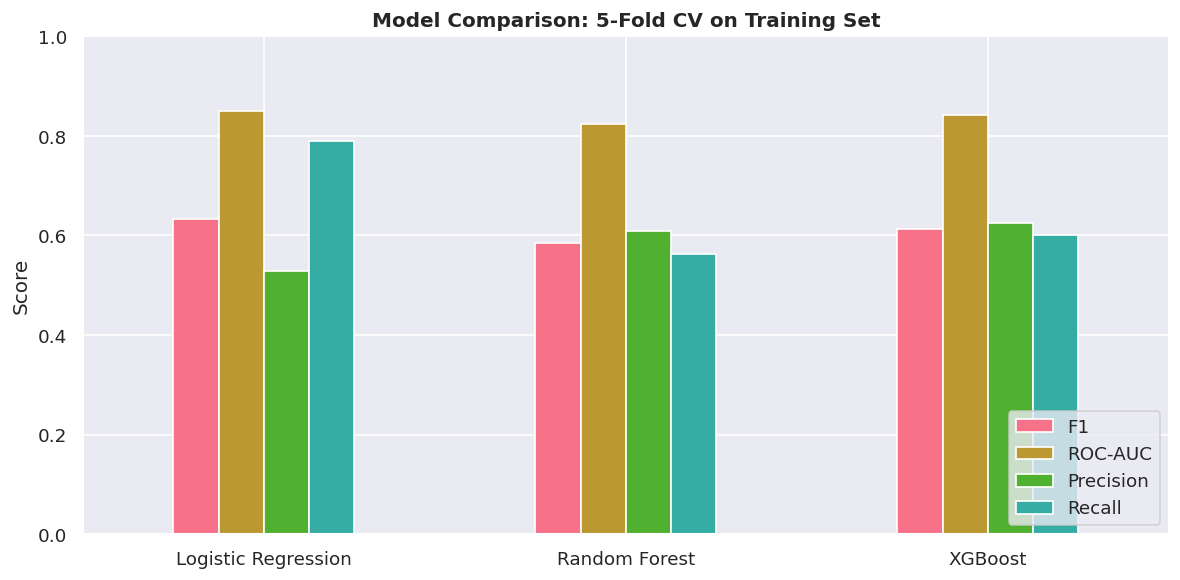

Best model by CV ROC-AUC: Logistic Regression


In [48]:
summary.plot(kind='bar', figsize=(10, 5), edgecolor='white', rot=0)
plt.title('Model Comparison: 5-Fold CV on Training Set', fontweight='bold')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

best_name = summary['ROC-AUC'].idxmax()
print(f"Best model by CV ROC-AUC: {best_name}")

In [49]:
#final evaluation
from sklearn.metrics import (precision_score, recall_score,
                             roc_curve, precision_recall_curve,
                             average_precision_score)

fitted = {}
test_rows = {}

for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    fitted[name] = pipe

    proba = pipe.predict_proba(X_test)[:, 1]
    pred  = (proba >= 0.5).astype(int)

    test_rows[name] = {
        'F1':        f1_score(y_test, pred),
        'ROC-AUC':   roc_auc_score(y_test, proba),
        'Precision': precision_score(y_test, pred),
        'Recall':    recall_score(y_test, pred),
    }

test_summary = pd.DataFrame(test_rows).T.round(3)
print("Test-set results (threshold = 0.50):")
display(test_summary)

Test-set results (threshold = 0.50):


,F1,ROC-AUC,Precision,Recall
Logistic Regression,0.62,0.85,0.50,0.79
Random Forest,0.56,0.82,0.57,0.55
XGBoost,0.59,0.84,0.59,0.60


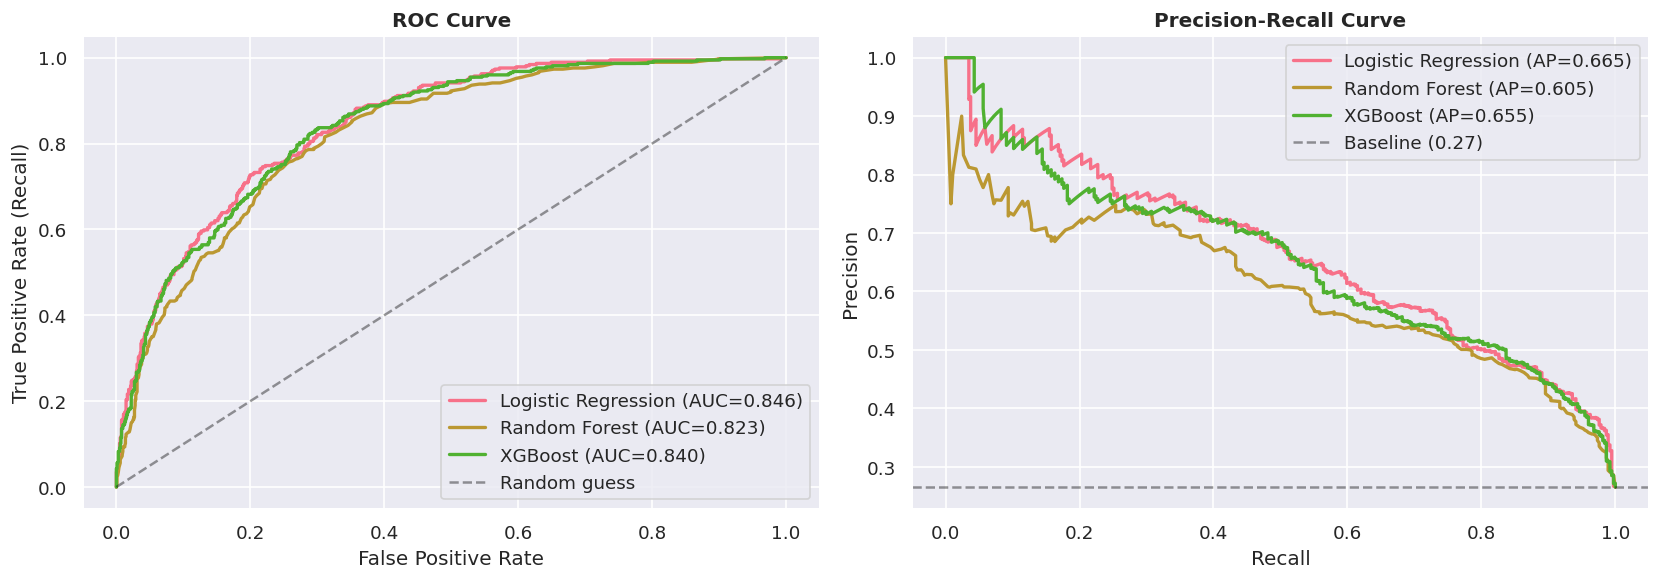

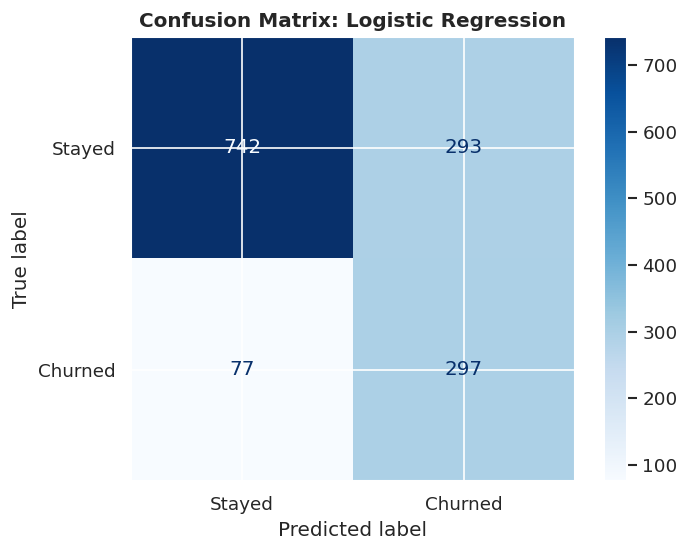

              precision    recall  f1-score   support

      Stayed       0.91      0.72      0.80      1035
     Churned       0.50      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.70      0.76      0.71      1409
weighted avg       0.80      0.74      0.75      1409



In [50]:
#ROC curve, precision-recall curve, confusion matrix

# ── ROC AND PR CURVES FOR ALL MODELS ──────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for name, pipe in fitted.items():
    proba = pipe.predict_proba(X_test)[:, 1]

    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[0].plot(fpr, tpr, lw=2,
                 label=f"{name} (AUC={roc_auc_score(y_test, proba):.3f})")

    prec, rec, _ = precision_recall_curve(y_test, proba)
    axes[1].plot(rec, prec, lw=2,
                 label=f"{name} (AP={average_precision_score(y_test, proba):.3f})")

axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.4, label='Random guess')
axes[0].set_title('ROC Curve', fontweight='bold')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate (Recall)')
axes[0].legend(loc='lower right')

axes[1].axhline(y_test.mean(), ls='--', color='k', alpha=0.4,
                label=f'Baseline ({y_test.mean():.2f})')
axes[1].set_title('Precision-Recall Curve', fontweight='bold')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].legend(loc='upper right')

plt.tight_layout()
plt.show()

# ── CONFUSION MATRIX + REPORT FOR THE BEST MODEL ──────
best_pipe = fitted[best_name]

ConfusionMatrixDisplay.from_estimator(
    best_pipe, X_test, y_test,
    display_labels=['Stayed', 'Churned'], cmap='Blues'
)
plt.title(f'Confusion Matrix: {best_name}', fontweight='bold')
plt.show()

print(classification_report(y_test, best_pipe.predict(X_test),
                            target_names=['Stayed', 'Churned']))

In [51]:
from sklearn.model_selection import cross_val_predict

# ── OUT-OF-FOLD PROBABILITIES ON THE TRAIN SET ────────
# Every training row gets a prediction from a model that never saw it
oof_proba = cross_val_predict(
    pipelines[best_name], X_train, y_train,
    cv=cv, method='predict_proba', n_jobs=-1
)[:, 1]

# ── FIND THE THRESHOLD THAT MAXIMISES F1 ──────────────
prec, rec, thr = precision_recall_curve(y_train, oof_proba)
f1_scores = 2 * prec * rec / (prec + rec + 1e-9)
best_idx  = np.argmax(f1_scores[:-1])     # last point has no threshold
best_thr  = thr[best_idx]
print(f"Threshold chosen on TRAIN (out-of-fold): {best_thr:.2f}")

# ── APPLY BOTH THRESHOLDS TO THE TEST SET ─────────────
test_proba = best_pipe.predict_proba(X_test)[:, 1]

rows = {}
for label, t in [('Default (0.50)', 0.50), (f'Tuned ({best_thr:.2f})', best_thr)]:
    pred = (test_proba >= t).astype(int)
    rows[label] = {
        'Precision': precision_score(y_test, pred),
        'Recall':    recall_score(y_test, pred),
        'F1':        f1_score(y_test, pred),
        'Customers flagged': int(pred.sum()),
    }

display(pd.DataFrame(rows).T.round(3))

Threshold chosen on TRAIN (out-of-fold): 0.60


,Precision,Recall,F1,Customers flagged
Default (0.50),0.50,0.79,0.62,590.00
Tuned (0.60),0.57,0.73,0.64,479.00


In [52]:
from sklearn.model_selection import RandomizedSearchCV, cross_val_predict
from scipy.stats import randint, uniform, loguniform

# ── SEARCH SPACES (one per model; we only run the winner) ──
# Note the naming: stepname__parameter
param_spaces = {
    'XGBoost': {
        'classifier__n_estimators':     randint(150, 500),
        'classifier__learning_rate':    loguniform(0.01, 0.2),
        'classifier__max_depth':        randint(3, 8),
        'classifier__subsample':        uniform(0.6, 0.4),      # 0.6 to 1.0
        'classifier__colsample_bytree': uniform(0.6, 0.4),      # 0.6 to 1.0
        'classifier__min_child_weight': randint(1, 8),
        'classifier__reg_lambda':       loguniform(0.5, 10),
        'smote__k_neighbors':           randint(3, 10),
    },
    'Random Forest': {
        'classifier__n_estimators':      randint(200, 500),
        'classifier__max_depth':         [None, 6, 10, 14, 20],
        'classifier__min_samples_split': randint(2, 20),
        'classifier__min_samples_leaf':  randint(1, 10),
        'classifier__max_features':      ['sqrt', 'log2', 0.3],
        'smote__k_neighbors':            randint(3, 10),
    },
    'Logistic Regression': {
        'classifier__C':      loguniform(1e-3, 1e2),
        'smote__k_neighbors': randint(3, 10),
    },
}

# ── RUN THE SEARCH ────────────────────────────────────
print(f"Tuning: {best_name}")

search = RandomizedSearchCV(
    estimator=pipelines[best_name],
    param_distributions=param_spaces[best_name],
    n_iter=20,              # 20 random configurations
    scoring='roc_auc',
    cv=cv,                  # same stratified 5-fold as before
    n_jobs=-1,
    random_state=42,
    refit=True,             # refit best config on the full train set
    verbose=1
)

search.fit(X_train, y_train)
print(f"Best CV ROC-AUC: {search.best_score_:.4f}")
print("\nBest parameters:")
for k, v in search.best_params_.items():
    v = f"{v:.4g}" if isinstance(v, float) else v
    print(f"  {k:32} {v}")

Tuning: Logistic Regression
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Best CV ROC-AUC: 0.8499

Best parameters:
  classifier__C                    0.01153
  smote__k_neighbors               6


,rank_test_score,mean_test_score,std_test_score,param_classifier__C,param_smote__k_neighbors
8,1,0.85,0.01,0.01,6
1,2,0.85,0.01,0.01,7
9,3,0.85,0.01,0.01,6
16,4,0.85,0.01,1.24,6
13,5,0.85,0.01,0.01,6


Untuned CV ROC-AUC : 0.8490
Tuned   CV ROC-AUC : 0.8499
Improvement        : +0.0009


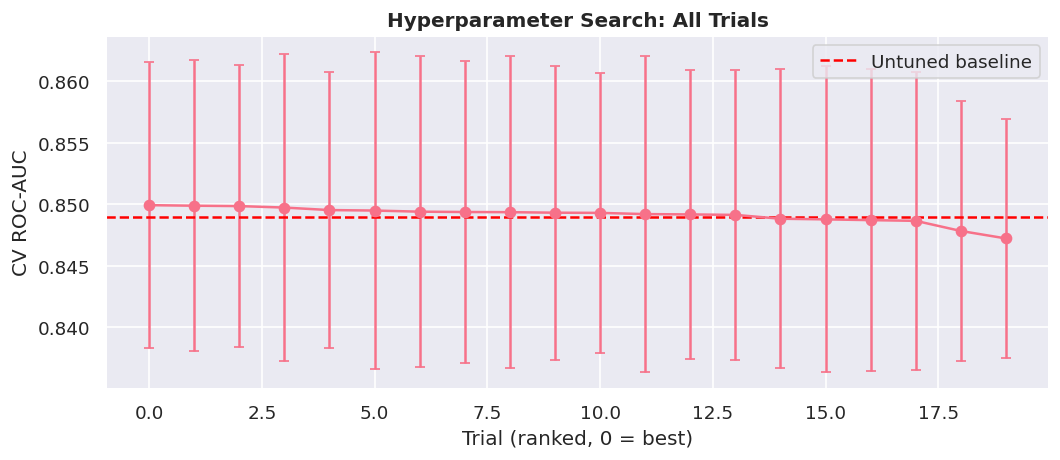

In [53]:
res = pd.DataFrame(search.cv_results_).sort_values('rank_test_score')

# ── TOP 5 CONFIGURATIONS ──────────────────────────────
cols = ['rank_test_score', 'mean_test_score', 'std_test_score'] + \
       [c for c in res.columns if c.startswith('param_')]
display(res[cols].head(5).round(4))

# ── BEFORE vs AFTER (cross-validation) ────────────────
baseline = summary.loc[best_name, 'ROC-AUC']
tuned    = search.best_score_
print(f"Untuned CV ROC-AUC : {baseline:.4f}")
print(f"Tuned   CV ROC-AUC : {tuned:.4f}")
print(f"Improvement        : {tuned - baseline:+.4f}")

# ── ALL 20 TRIALS, BEST TO WORST ──────────────────────
plt.figure(figsize=(9, 4))
plt.errorbar(range(len(res)), res['mean_test_score'],
             yerr=res['std_test_score'], fmt='o-', capsize=3)
plt.axhline(baseline, color='red', ls='--', label='Untuned baseline')
plt.xlabel('Trial (ranked, 0 = best)')
plt.ylabel('CV ROC-AUC')
plt.title('Hyperparameter Search: All Trials', fontweight='bold')
plt.legend()
plt.tight_layout()
plt.show()

FINAL MODEL: Logistic Regression (tuned)
---------------------------------------------
  Test ROC-AUC, untuned : 0.846
  Test ROC-AUC, tuned   : 0.847
  Decision threshold    : 0.56
  Precision             : 0.562
  Recall                : 0.743
  F1                    : 0.640

              precision    recall  f1-score   support

      Stayed       0.89      0.79      0.84      1035
     Churned       0.56      0.74      0.64       374

    accuracy                           0.78      1409
   macro avg       0.73      0.77      0.74      1409
weighted avg       0.81      0.78      0.79      1409



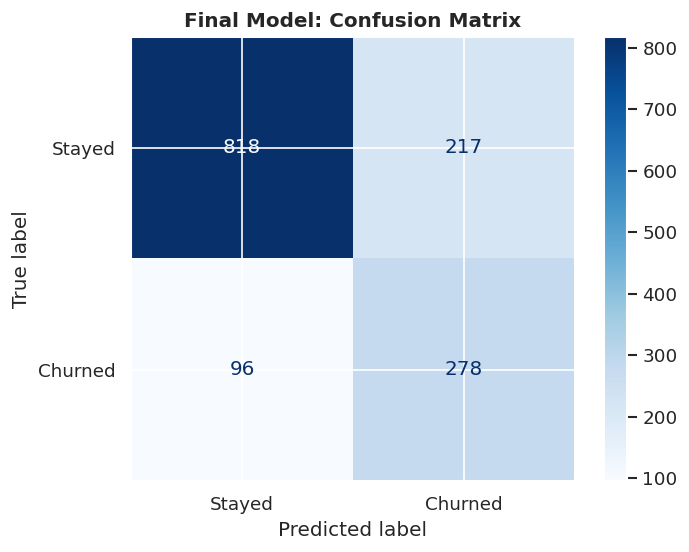

In [54]:
tuned_model = search.best_estimator_

# ── RE-TUNE THE THRESHOLD FOR THE TUNED MODEL ─────────
# Out-of-fold probabilities on TRAIN only (no test leakage)
oof = cross_val_predict(tuned_model, X_train, y_train, cv=cv,
                        method='predict_proba', n_jobs=-1)[:, 1]

prec, rec, thr = precision_recall_curve(y_train, oof)
f1s = 2 * prec * rec / (prec + rec + 1e-9)
final_thr = thr[np.argmax(f1s[:-1])]

# ── EVALUATE ON THE TEST SET ──────────────────────────
proba = tuned_model.predict_proba(X_test)[:, 1]
pred  = (proba >= final_thr).astype(int)

print(f"FINAL MODEL: {best_name} (tuned)")
print("-" * 45)
print(f"  Test ROC-AUC, untuned : {test_summary.loc[best_name, 'ROC-AUC']:.3f}")
print(f"  Test ROC-AUC, tuned   : {roc_auc_score(y_test, proba):.3f}")
print(f"  Decision threshold    : {final_thr:.2f}")
print(f"  Precision             : {precision_score(y_test, pred):.3f}")
print(f"  Recall                : {recall_score(y_test, pred):.3f}")
print(f"  F1                    : {f1_score(y_test, pred):.3f}")
print()
print(classification_report(y_test, pred, target_names=['Stayed', 'Churned']))

ConfusionMatrixDisplay.from_predictions(
    y_test, pred, display_labels=['Stayed', 'Churned'], cmap='Blues'
)
plt.title('Final Model: Confusion Matrix', fontweight='bold')
plt.show()

In [55]:
import joblib, json, sklearn, imblearn, xgboost
from google.colab import files

# ── SAVE THE WHOLE PIPELINE (preprocessing + model) ───
joblib.dump(tuned_model, 'churn_model.joblib')

# ── SAVE EVERYTHING THE APP NEEDS TO USE IT CORRECTLY ─
config = {
    'model_name':      best_name,
    'threshold':       float(final_thr),
    'feature_columns': X_train.columns.tolist(),
    'versions': {
        'scikit-learn':  sklearn.__version__,
        'imbalanced-learn': imblearn.__version__,
        'xgboost':       xgboost.__version__,
    }
}
with open('model_config.json', 'w') as f:
    json.dump(config, f, indent=2)

print("Saved: churn_model.joblib, model_config.json")
print(json.dumps(config['versions'], indent=2))

files.download('churn_model.joblib')
files.download('model_config.json')

Saved: churn_model.joblib, model_config.json
{
  "scikit-learn": "1.6.1",
  "imbalanced-learn": "0.14.2",
  "xgboost": "3.4.1"
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

SHAP

In [56]:
# ── INSTALL (first time we need it) ───────────────────
!pip install shap --quiet
import shap

# ── PULL THE PIECES OUT OF THE FITTED PIPELINE ────────
# SMOTE only runs during training, so for explaining we need
# just the preprocessor and the classifier
prep = tuned_model.named_steps['preprocessor']
clf  = tuned_model.named_steps['classifier']

X_train_t = prep.transform(X_train)
X_test_t  = prep.transform(X_test)

# Readable feature names: 'cat__Contract_Month-to-month' -> 'Contract_Month-to-month'
feature_names = [n.split('__', 1)[-1] for n in prep.get_feature_names_out()]
X_test_df = pd.DataFrame(X_test_t, columns=feature_names)

# ── PICK THE RIGHT EXPLAINER FOR THE MODEL TYPE ───────
if best_name in ('XGBoost', 'Random Forest'):
    explainer = shap.TreeExplainer(clf)
else:
    explainer = shap.LinearExplainer(clf, X_train_t)

raw = explainer.shap_values(X_test_t)

# Different SHAP versions return different shapes; normalise to (rows, features)
if isinstance(raw, list):
    sv = raw[1]                 # older versions: list of per-class arrays
elif np.ndim(raw) == 3:
    sv = raw[:, :, 1]           # newer versions: (rows, features, classes)
else:
    sv = raw

ev = explainer.expected_value
base_value = float(np.ravel(ev)[-1]) if np.ndim(ev) > 0 else float(ev)

# ── SANITY CHECK: base value + SHAP values = model output ─
recon = base_value + sv.sum(axis=1)
if best_name != 'Random Forest':
    recon = 1 / (1 + np.exp(-recon))       # log-odds -> probability
err = np.abs(recon - clf.predict_proba(X_test_t)[:, 1]).max()

print(f"SHAP matrix shape : {sv.shape}")
print(f"Max reconstruction error: {err:.5f}   (should be very close to 0)")

SHAP matrix shape : (1409, 48)
Max reconstruction error: 0.00000   (should be very close to 0)


Top 10 features by mean |SHAP|:


,mean |SHAP|
Contract_Month-to-month,0.27
tenure,0.25
charges_ratio,0.21
MonthlyCharges,0.19
monthly_charge_above_avg,0.19
PaperlessBilling,0.17
Contract_Two year,0.17
is_high_risk,0.16
InternetService_Fiber optic,0.15
PaymentMethod_Electronic check,0.14


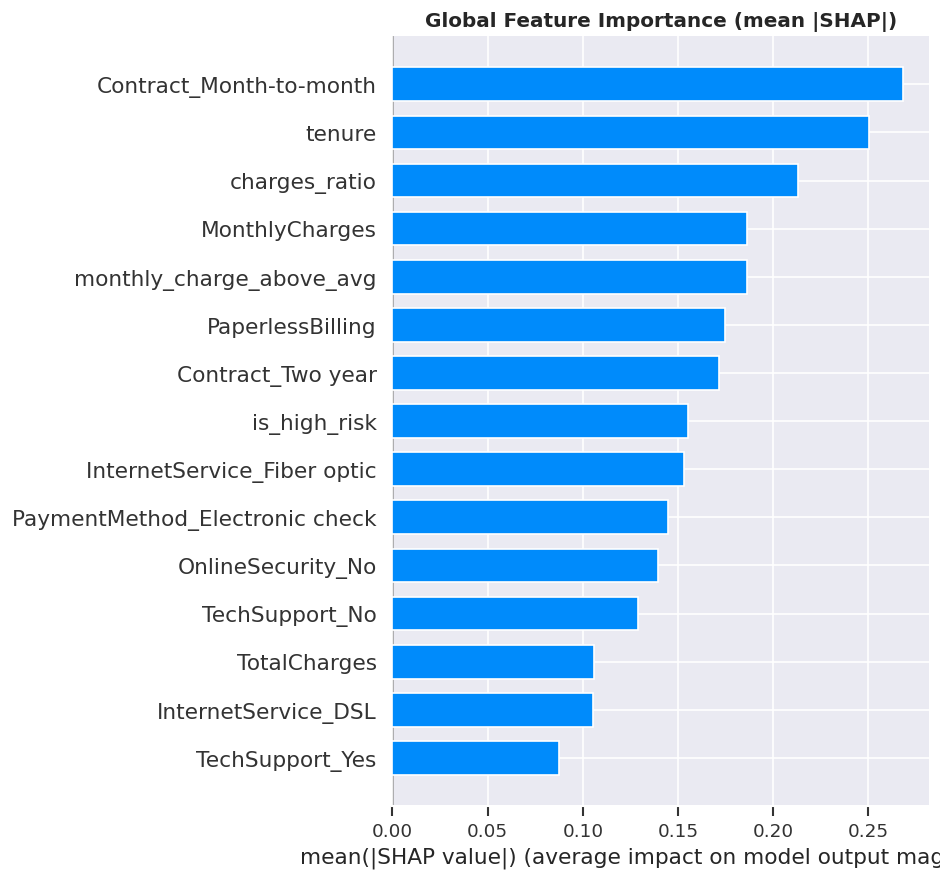

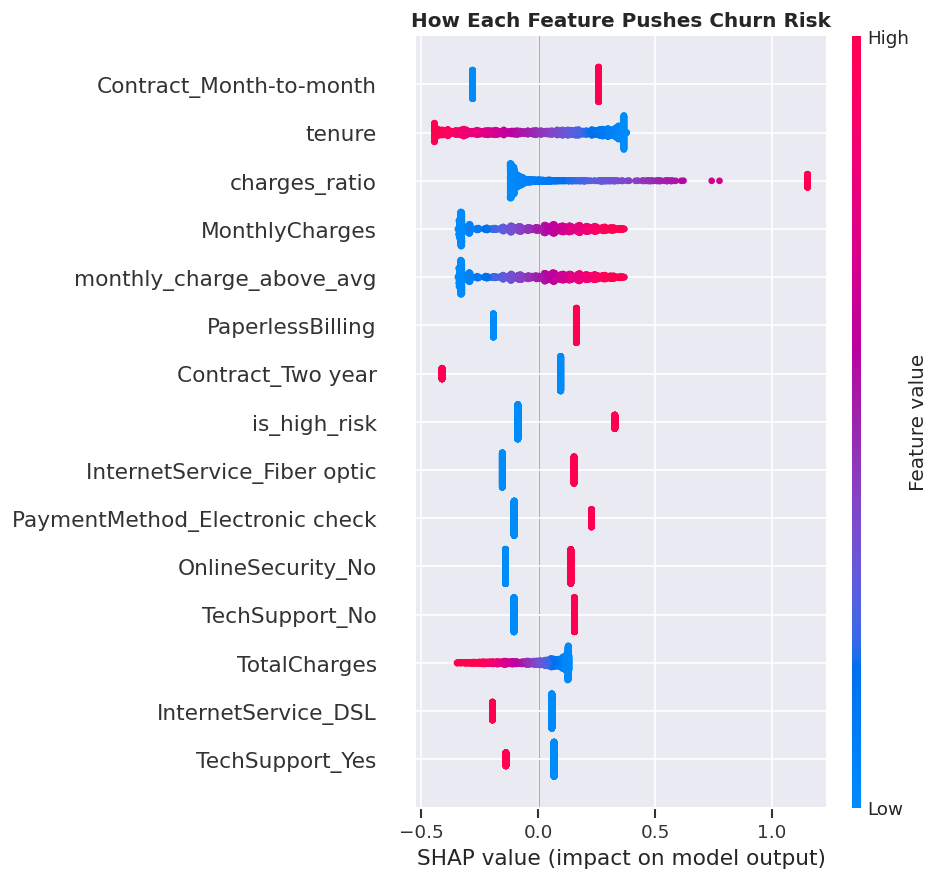


Engineered features (rank out of 48 ):
  # 3  charges_ratio
  # 5  monthly_charge_above_avg
  # 8  is_high_risk
  #30  tenure_group_12-24m
  #31  tenure_group_48-72m
  #44  tenure_group_24-48m
  #45  num_services
  #48  tenure_group_0-12m


In [57]:
# ── MEAN ABSOLUTE SHAP = OVERALL IMPORTANCE ───────────
importance = pd.Series(np.abs(sv).mean(axis=0), index=feature_names) \
               .sort_values(ascending=False)

print("Top 10 features by mean |SHAP|:")
display(importance.head(10).round(4).to_frame('mean |SHAP|'))

# ── BAR CHART ─────────────────────────────────────────
shap.summary_plot(sv, X_test_df, plot_type='bar', max_display=15, show=False)
plt.title('Global Feature Importance (mean |SHAP|)', fontweight='bold')
plt.tight_layout()
plt.show()

# ── BEESWARM: IMPORTANCE + DIRECTION ──────────────────
shap.summary_plot(sv, X_test_df, max_display=15, show=False)
plt.title('How Each Feature Pushes Churn Risk', fontweight='bold')
plt.tight_layout()
plt.show()

# ── DID MY ENGINEERED FEATURES MATTER? ────────────────
ranks = importance.rank(ascending=False).astype(int)
engineered = ('is_high_risk', 'charges_ratio', 'num_services',
              'monthly_charge_above_avg', 'tenure_group')
print("\nEngineered features (rank out of", len(ranks), "):")
for f in ranks.index:
    if f.startswith(engineered):
        print(f"  #{ranks[f]:>2}  {f}")

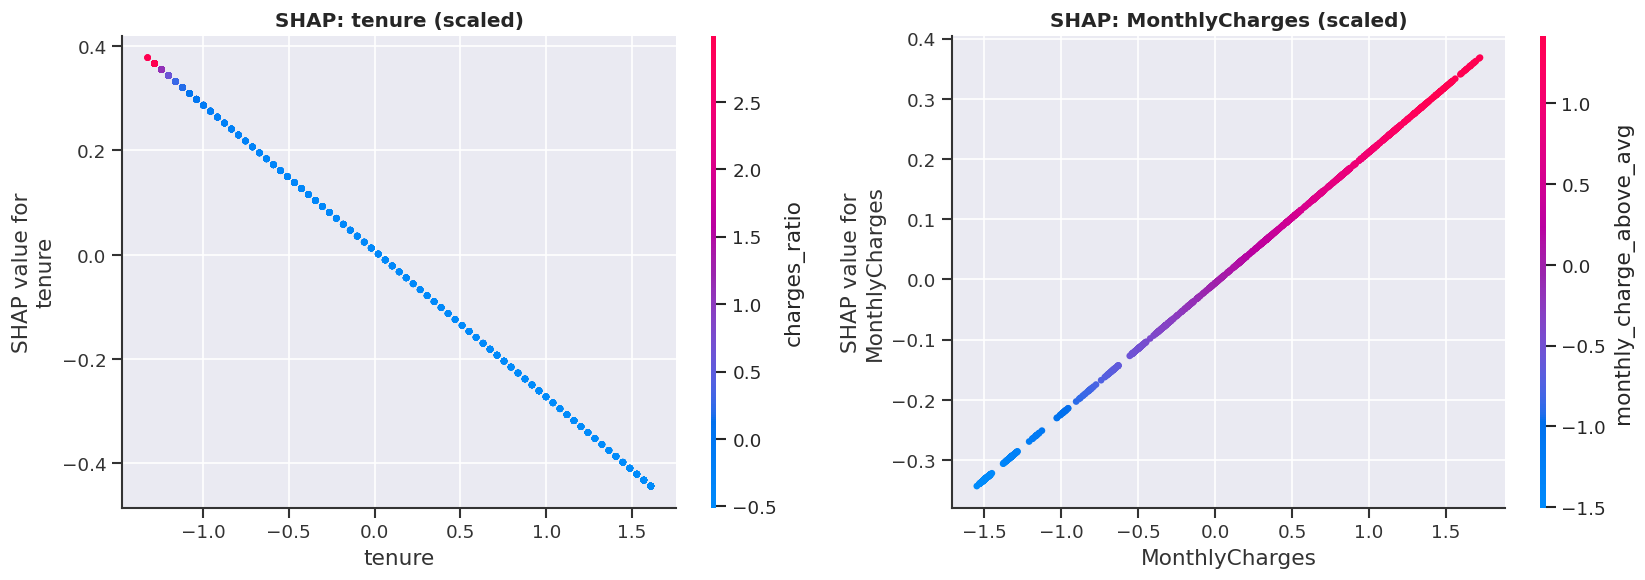

In [58]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

shap.dependence_plot('tenure', sv, X_test_df,
                     ax=axes[0], show=False)
axes[0].set_title('SHAP: tenure (scaled)', fontweight='bold')

shap.dependence_plot('MonthlyCharges', sv, X_test_df,
                     ax=axes[1], show=False)
axes[1].set_title('SHAP: MonthlyCharges (scaled)', fontweight='bold')

plt.tight_layout()
plt.show()

Customer #1090: predicted churn probability 98%
  Pushing risk UP:
    + charges_ratio = 1.00   (+1.15)
    + tenure = 1.00   (+0.37)
    + is_high_risk = 1.00   (+0.33)
  Pushing risk DOWN:
    - PhoneService = 1.00   (-0.05)
    - tenure_group_12-24m   (-0.02)

Customer #147: predicted churn probability 56%
  Pushing risk UP:
    + Contract_Month-to-month   (+0.26)
    + PaymentMethod_Electronic check   (+0.23)
    + MonthlyCharges = 96.75   (+0.22)
  Pushing risk DOWN:
    - tenure = 55.00   (-0.25)
    - OnlineSecurity_Yes   (-0.17)

Customer #955: predicted churn probability 2%
  Pushing risk UP:
    + Partner = 1.00   (+0.03)
    + PaymentMethod_Mailed check   (+0.02)
    + PaymentMethod_Bank transfer (automatic)   (+0.02)
  Pushing risk DOWN:
    - tenure = 71.00   (-0.43)
    - Contract_Two year   (-0.41)



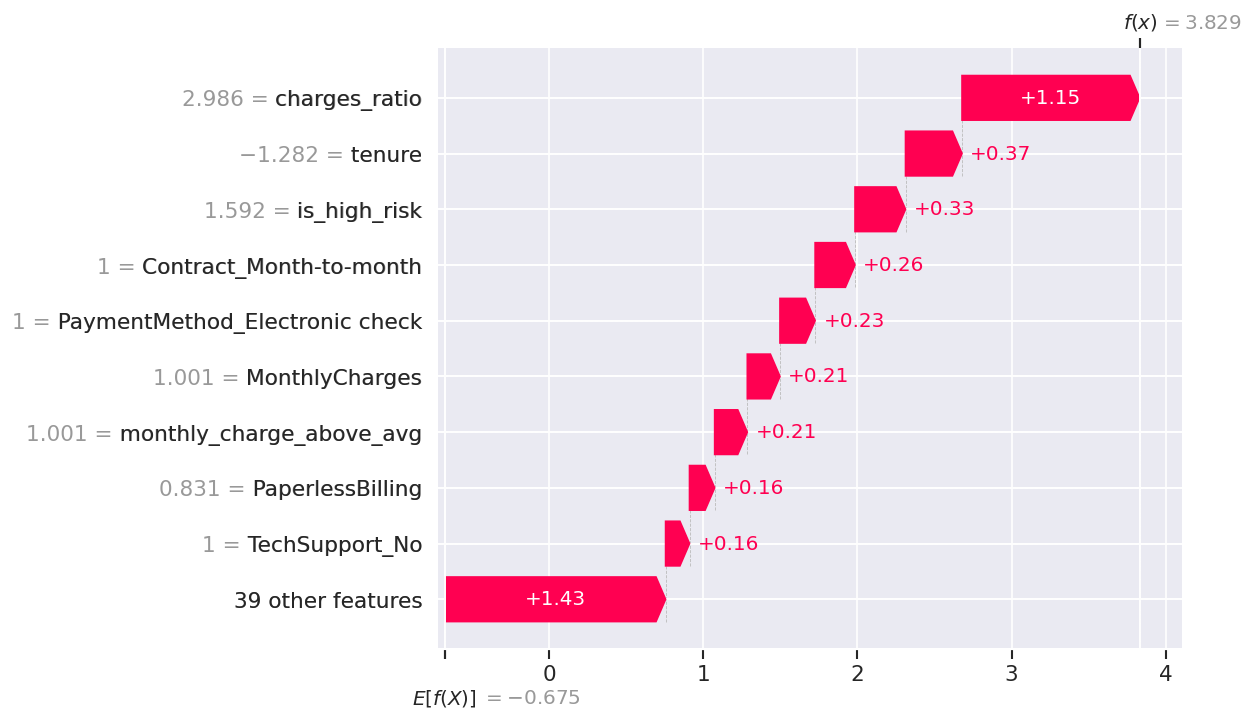

In [59]:
proba = tuned_model.predict_proba(X_test)[:, 1]

def explain_customer(i, top_k=3):
    """Print a plain-English explanation for test customer i."""
    contrib = pd.Series(sv[i], index=feature_names)
    row = X_test.iloc[i]

    def describe(f):
        # numeric features: show the real (unscaled) value; one-hot: show the name
        return f"{f} = {row[f]:.2f}" if f in X_test.columns else f

    print(f"Customer #{i}: predicted churn probability {proba[i]:.0%}")
    print("  Pushing risk UP:")
    for f, v in contrib.sort_values(ascending=False).head(top_k).items():
        print(f"    + {describe(f)}   ({v:+.2f})")
    print("  Pushing risk DOWN:")
    for f, v in contrib.sort_values().head(2).items():
        print(f"    - {describe(f)}   ({v:+.2f})")
    print()

# ── THREE CONTRASTING CUSTOMERS ───────────────────────
hi  = int(np.argmax(proba))                        # most at-risk
lo  = int(np.argmin(proba))                        # safest
mid = int(np.argmin(np.abs(proba - final_thr)))    # borderline

for i in (hi, mid, lo):
    explain_customer(i)

# ── WATERFALL FOR THE HIGHEST-RISK CUSTOMER ───────────
exp = shap.Explanation(
    values=sv[hi],
    base_values=base_value,
    data=X_test_df.iloc[hi].values,
    feature_names=feature_names
)
shap.plots.waterfall(exp, max_display=10)

In [60]:
%%writefile features.py
import numpy as np
import pandas as pd


def add_engineered_features(df, avg_monthly_charge):
    """Create the engineered features exactly as in the training notebook.

    Input : DataFrame with the original (cleaned, binary-encoded) columns.
    Output: a copy with 5 extra columns.
    """
    out = df.copy()

    out['tenure_group'] = pd.cut(
        out['tenure'],
        bins=[0, 12, 24, 48, 72],
        labels=['0-12m', '13-24m', '25-48m', '49-72m']
    )

    with np.errstate(divide='ignore', invalid='ignore'):
        out['charges_ratio'] = np.where(
            out['TotalCharges'] > 0,
            out['MonthlyCharges'] / out['TotalCharges'],
            1.0
        )

    out['num_services'] = out[['PhoneService', 'PaperlessBilling',
                               'Partner', 'Dependents']].sum(axis=1)

    out['is_high_risk'] = (
        (out['Contract'] == 'Month-to-month') & (out['tenure'] <= 12)
    ).astype(int)

    out['monthly_charge_above_avg'] = out['MonthlyCharges'] - avg_monthly_charge

    return out

Writing features.py


In [61]:
import json, os, platform, importlib
import joblib, shap
import features
importlib.reload(features)

ENGINEERED = ['tenure_group', 'charges_ratio', 'num_services',
              'is_high_risk', 'monthly_charge_above_avg']

# Same constant that was used in Step 4
avg_charge = float(df['MonthlyCharges'].mean())

# ── 1. DOES features.py REPRODUCE THE NOTEBOOK'S FEATURES? ──
raw_cols = [c for c in X_test.columns if c not in ENGINEERED]
rebuilt  = features.add_engineered_features(X_test[raw_cols], avg_charge)

print("Feature check:")
for c in ENGINEERED:
    if c == 'tenure_group':
        same = (X_test[c].astype(str).values == rebuilt[c].astype(str).values).all()
    else:
        same = np.allclose(X_test[c].astype(float), rebuilt[c].astype(float))
    print(f"  {c:26} {'OK' if same else 'MISMATCH'}")

p_old = tuned_model.predict_proba(X_test)[:, 1]
p_new = tuned_model.predict_proba(rebuilt[X_test.columns])[:, 1]
print(f"Max prediction difference: {np.abs(p_old - p_new).max():.2e}  (should be ~0)")

# ── 2. EXTEND THE CONFIG FROM STEP 7 ──────────────────
with open('model_config.json') as f:
    config = json.load(f)

config['avg_monthly_charge']        = avg_charge
config['transformed_feature_names'] = feature_names
config['python_version']            = platform.python_version()
config['versions'].update({
    'shap': shap.__version__,
    'pandas': pd.__version__,
    'numpy': np.__version__,
})
with open('model_config.json', 'w') as f:
    json.dump(config, f, indent=2)

np.save('shap_background.npy', X_train_t[:200])

# ── 3. GENERATE requirements.txt WITH PINNED VERSIONS ──
v = config['versions']
lines = [
    'streamlit',
    f"pandas=={v['pandas']}",
    f"numpy=={v['numpy']}",
    f"scikit-learn=={v['scikit-learn']}",
    f"imbalanced-learn=={v['imbalanced-learn']}",
    f"shap=={v['shap']}",
    'matplotlib',
    'joblib',
]
if config['model_name'] == 'XGBoost':
    lines.append(f"xgboost=={v['xgboost']}")

with open('requirements.txt', 'w') as f:
    f.write('\n'.join(lines) + '\n')

# ── 4. FILE SIZE CHECK (GitHub browser upload limit) ──
size_mb = os.path.getsize('churn_model.joblib') / 1e6
if size_mb > 20:
    joblib.dump(tuned_model, 'churn_model.joblib', compress=3)
    size_mb = os.path.getsize('churn_model.joblib') / 1e6

print("\nrequirements.txt:")
print(open('requirements.txt').read())
print(f"churn_model.joblib size: {size_mb:.1f} MB")
if size_mb > 25:
    print("WARNING: over GitHub's ~25 MB browser-upload limit. Pick XGBoost or reduce n_estimators.")
print(f"\nPYTHON VERSION IN COLAB: {platform.python_version()}  <-- remember this for deployment")

Feature check:
  tenure_group               MISMATCH
  charges_ratio              OK
  num_services               OK
  is_high_risk               OK
  monthly_charge_above_avg   OK
Max prediction difference: 2.38e-02  (should be ~0)

requirements.txt:
streamlit
pandas==2.2.3
numpy==2.1.3
scikit-learn==1.6.1
imbalanced-learn==0.14.2
shap==0.54.1
matplotlib
joblib

churn_model.joblib size: 0.6 MB

PYTHON VERSION IN COLAB: 3.13.18  <-- remember this for deployment


In [62]:
loaded = joblib.load('churn_model.joblib')
cfg    = json.load(open('model_config.json'))

def make_row(**overrides):
    row = dict(gender=1, SeniorCitizen=0, Partner=0, Dependents=0, tenure=3,
               PhoneService=1, MultipleLines='No', InternetService='Fiber optic',
               OnlineSecurity='No', OnlineBackup='No', DeviceProtection='No',
               TechSupport='No', StreamingTV='No', StreamingMovies='No',
               Contract='Month-to-month', PaperlessBilling=1,
               PaymentMethod='Electronic check',
               MonthlyCharges=85.0, TotalCharges=255.0)
    row.update(overrides)
    return pd.DataFrame([row])

profiles = {
    'Expected HIGH risk': make_row(),
    'Expected LOW risk':  make_row(
        tenure=60, Contract='Two year', InternetService='DSL',
        PaymentMethod='Credit card (automatic)', Partner=1, Dependents=1,
        MonthlyCharges=55.0, TotalCharges=3300.0, PaperlessBilling=0),
}

print("Smoke test:")
for label, r in profiles.items():
    Xr = features.add_engineered_features(r, cfg['avg_monthly_charge'])[cfg['feature_columns']]
    s = loaded.predict_proba(Xr)[0, 1]
    print(f"  {label:20} score = {s:.0%}   flagged = {s >= cfg['threshold']}")

# ── CATEGORY VALUES THE MODEL LEARNED (app dropdowns must match) ──
ohe = loaded.named_steps['preprocessor'].named_transformers_['cat'].named_steps['encoder']
print("\nCategories the model knows:")
for col, cats in zip(cat_cols, ohe.categories_):
    print(f"  {col:18} {list(cats)}")

Smoke test:
  Expected HIGH risk   score = 88%   flagged = True
  Expected LOW risk    score = 7%   flagged = False

Categories the model knows:
  MultipleLines      ['No', 'No phone service', 'Yes']
  InternetService    ['DSL', 'Fiber optic', 'No']
  OnlineSecurity     ['No', 'No internet service', 'Yes']
  OnlineBackup       ['No', 'No internet service', 'Yes']
  DeviceProtection   ['No', 'No internet service', 'Yes']
  TechSupport        ['No', 'No internet service', 'Yes']
  StreamingTV        ['No', 'No internet service', 'Yes']
  StreamingMovies    ['No', 'No internet service', 'Yes']
  Contract           ['Month-to-month', 'One year', 'Two year']
  PaymentMethod      ['Bank transfer (automatic)', 'Credit card (automatic)', 'Electronic check', 'Mailed check']
  tenure_group       ['0-12m', '12-24m', '24-48m', '48-72m']


In [63]:
%%writefile app.py
import json

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import streamlit as st

from features import add_engineered_features

try:
    import shap
    SHAP_OK = True
except Exception:
    SHAP_OK = False

st.set_page_config(page_title="Customer Churn Predictor",
                   page_icon="📉", layout="wide")


@st.cache_resource
def load_artifacts():
    model = joblib.load("churn_model.joblib")
    with open("model_config.json") as f:
        cfg = json.load(f)
    prep = model.named_steps["preprocessor"]
    clf = model.named_steps["classifier"]

    explainer = None
    if SHAP_OK:
        try:
            if cfg["model_name"] in ("XGBoost", "Random Forest"):
                explainer = shap.TreeExplainer(clf)
            else:
                explainer = shap.LinearExplainer(clf, np.load("shap_background.npy"))
        except Exception:
            explainer = None
    return model, prep, cfg, explainer


model, prep, cfg, explainer = load_artifacts()
THRESHOLD = cfg["threshold"]
AVG_CHARGE = cfg["avg_monthly_charge"]
YES_NO = {"Yes": 1, "No": 0}

st.title("📉 Customer Churn Predictor")
st.caption("Enter a customer's details in the sidebar. The model estimates "
           "churn risk and shows which factors drive it.")

# ───────────────────── SIDEBAR INPUTS ─────────────────────
with st.sidebar:
    st.header("Customer details")

    with st.expander("Account", expanded=True):
        tenure = st.slider("Tenure (months)", 0, 72, 3)
        contract = st.selectbox("Contract", ["Month-to-month", "One year", "Two year"])
        payment = st.selectbox("Payment method", [
            "Electronic check", "Mailed check",
            "Bank transfer (automatic)", "Credit card (automatic)"])
        paperless = st.selectbox("Paperless billing", ["Yes", "No"])
        monthly = st.number_input("Monthly charges", min_value=0.0,
                                  max_value=200.0, value=85.0, step=1.0)
        auto_total = st.checkbox("Estimate total charges (monthly × tenure)", value=True)
        if auto_total:
            total = monthly * tenure
        else:
            total = st.number_input("Total charges", min_value=0.0,
                                    value=float(monthly * tenure), step=10.0)

    with st.expander("Services"):
        phone = st.selectbox("Phone service", ["Yes", "No"])
        multiple = (st.selectbox("Multiple lines", ["No", "Yes"])
                    if phone == "Yes" else "No phone service")
        internet = st.selectbox("Internet service", ["Fiber optic", "DSL", "No"])

        addon_labels = {
            "OnlineSecurity": "Online security",
            "OnlineBackup": "Online backup",
            "DeviceProtection": "Device protection",
            "TechSupport": "Tech support",
            "StreamingTV": "Streaming TV",
            "StreamingMovies": "Streaming movies",
        }
        addons = {}
        for col, label in addon_labels.items():
            if internet == "No":
                addons[col] = "No internet service"
            else:
                addons[col] = st.selectbox(label, ["No", "Yes"])

    with st.expander("Demographics"):
        gender = st.selectbox("Gender", ["Female", "Male"])
        senior = st.selectbox("Senior citizen", ["No", "Yes"])
        partner = st.selectbox("Has partner", ["No", "Yes"])
        dependents = st.selectbox("Has dependents", ["No", "Yes"])

# ───────────────────── BUILD THE MODEL INPUT ─────────────────────
raw = pd.DataFrame([{
    "gender": 1 if gender == "Male" else 0,
    "SeniorCitizen": YES_NO[senior],
    "Partner": YES_NO[partner],
    "Dependents": YES_NO[dependents],
    "tenure": tenure,
    "PhoneService": YES_NO[phone],
    "MultipleLines": multiple,
    "InternetService": internet,
    **addons,
    "Contract": contract,
    "PaperlessBilling": YES_NO[paperless],
    "PaymentMethod": payment,
    "MonthlyCharges": monthly,
    "TotalCharges": total,
}])

X_row = add_engineered_features(raw, AVG_CHARGE)[cfg["feature_columns"]]
score = float(model.predict_proba(X_row)[0, 1])
flagged = score >= THRESHOLD

# ───────────────────── RESULTS ─────────────────────
left, right = st.columns([1, 1.5])

with left:
    st.subheader("Prediction")
    st.metric("Churn risk score", f"{score:.0%}")
    st.progress(min(max(score, 0.0), 1.0))
    if flagged:
        st.error(f"⚠️ High risk: above the model's decision threshold ({THRESHOLD:.0%}).")
    else:
        st.success(f"✅ Lower risk: below the model's decision threshold ({THRESHOLD:.0%}).")
    st.caption("This is a risk score, not a calibrated probability. The model was "
               "trained on resampled (SMOTE) data, so scores run higher than the "
               "real-world churn rate. Use it to rank customers.")

with right:
    st.subheader("Why this score?")
    if explainer is None:
        st.info("Explanations are unavailable in this environment.")
    else:
        try:
            Xt = prep.transform(X_row)
            sv = explainer.shap_values(Xt)
            if isinstance(sv, list):
                vals = sv[1][0]
            elif np.ndim(sv) == 3:
                vals = sv[0, :, 1]
            else:
                vals = sv[0]

            contrib = pd.Series(vals, index=cfg["transformed_feature_names"])
            top = contrib.loc[contrib.abs().sort_values(ascending=False).head(8).index]

            fig, ax = plt.subplots(figsize=(6, 3.6))
            colors = ["#e74c3c" if v > 0 else "#3498db" for v in top.values[::-1]]
            ax.barh(list(top.index[::-1]), list(top.values[::-1]), color=colors)
            ax.axvline(0, color="grey", lw=0.8)
            ax.set_xlabel("Effect on risk score  (left lowers, right raises)")
            plt.tight_layout()
            st.pyplot(fig)
            plt.close(fig)

            ups = [n for n, v in contrib.sort_values(ascending=False).head(3).items() if v > 0]
            downs = [n for n, v in contrib.sort_values().head(2).items() if v < 0]
            if ups:
                st.markdown("**Raising risk:** " + ", ".join(f"`{n}`" for n in ups))
            if downs:
                st.markdown("**Lowering risk:** " + ", ".join(f"`{n}`" for n in downs))
        except Exception as e:
            st.warning(f"Could not compute the explanation: {e}")

# ───────────────────── WHAT-IF ─────────────────────
st.divider()
st.subheader("What-if: contract type")
rows = []
for c in ["Month-to-month", "One year", "Two year"]:
    alt = raw.copy()
    alt["Contract"] = c
    X_alt = add_engineered_features(alt, AVG_CHARGE)[cfg["feature_columns"]]
    rows.append({"Contract": c,
                 "Risk score": float(model.predict_proba(X_alt)[0, 1])})
st.bar_chart(pd.DataFrame(rows).set_index("Contract"))
st.caption("How the model's score changes if only the contract differs. This shows "
           "model sensitivity, not a guaranteed causal effect; confirming it would "
           "need an A/B test.")

st.caption(f"Model: {cfg['model_name']} · decision threshold {THRESHOLD:.2f} · "
           "trained on the Telco Customer Churn dataset")

Writing app.py


In [64]:
!zip -j churn_app.zip app.py features.py churn_model.joblib model_config.json shap_background.npy requirements.txt

from google.colab import files
files.download('churn_app.zip')

  adding: app.py (deflated 63%)
  adding: features.py (deflated 49%)
  adding: churn_model.joblib (deflated 88%)
  adding: model_config.json (deflated 69%)
  adding: shap_background.npy (deflated 88%)
  adding: requirements.txt (deflated 19%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [65]:
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score
from google.colab import files

APP_URL = "https://customer-churn-prediction-dhhpd8ezdjw2hwjl9qtget.streamlit.app/"

# ── NUMBERS FROM YOUR OWN RUN ─────────────────────────
test_proba = tuned_model.predict_proba(X_test)[:, 1]
test_pred  = (test_proba >= final_thr).astype(int)

n_rows      = len(df)
churn_rate  = df['Churn'].mean()
cv_auc_base = summary.loc[best_name, 'ROC-AUC']
cv_auc_tune = search.best_score_
t_auc       = roc_auc_score(y_test, test_proba)
t_prec      = precision_score(y_test, test_pred)
t_rec       = recall_score(y_test, test_pred)
t_f1        = f1_score(y_test, test_pred)

contract_rates = df.groupby('Contract')['Churn'].mean() * 100
tenure_means   = df.groupby('Churn')['tenure'].mean()
top_feats      = importance.head(5).index.tolist()

# ── README TEXT ───────────────────────────────────────
readme = f"""# Customer Churn Prediction

**Live demo:** {APP_URL}

An end-to-end machine learning project that predicts which telecom customers are likely to churn, explains *why*, and serves the model in a web app.

![App screenshot](assets/app_screenshot.png)

## Problem
Keeping a customer is cheaper than winning a new one, but a retention team cannot contact everyone. The goal is to **rank customers by churn risk** so the team can focus on the right people first, and to say what is driving each customer's risk.

## Dataset
Telco Customer Churn (Kaggle): {n_rows:,} customers, 19 raw features, about {churn_rate:.0%} churned (an imbalanced target).

## Approach
1. **Cleaning:** `TotalCharges` was stored as text with hidden blank strings that a normal null check misses. All affected rows were brand-new customers (tenure 0), so they were set to 0 instead of being imputed.
2. **EDA:** month-to-month contracts churn at about {contract_rates['Month-to-month']:.0f}% versus {contract_rates['Two year']:.0f}% for two-year contracts. Churned customers averaged {tenure_means[1]:.0f} months of tenure versus {tenure_means[0]:.0f} for retained customers.
3. **Feature engineering:** tenure bands, a charge ratio, and an interaction flag for new month-to-month customers, justified by the EDA findings.
4. **Class imbalance:** SMOTE applied *inside* the cross-validation pipeline (training folds only) plus class weights. Models are judged with F1, ROC-AUC and precision-recall curves rather than accuracy.
5. **Modelling:** Logistic Regression, Random Forest and XGBoost compared with stratified 5-fold cross-validation; the best model was tuned with RandomizedSearchCV.
6. **Decision threshold:** chosen on out-of-fold training predictions, so the test set was used only for final reporting.
7. **Explainability:** SHAP for global drivers and per-customer explanations.
8. **Deployment:** Streamlit app. Feature code lives in one module shared by the notebook and the app, to prevent training-serving skew.

## Results
| Metric | Value |
|---|---|
| Final model | {best_name} (tuned) |
| CV ROC-AUC before tuning (5-fold, train only) | {cv_auc_base:.3f} |
| CV ROC-AUC after tuning | {cv_auc_tune:.3f} |
| Test ROC-AUC | {t_auc:.3f} |
| Test precision / recall / F1 at threshold {final_thr:.2f} | {t_prec:.2f} / {t_rec:.2f} / {t_f1:.2f} |

Top drivers of predicted churn (mean absolute SHAP): `{', '.join(top_feats)}`.

## Limitations and next steps
- Scores are **not calibrated probabilities** (SMOTE and class weights inflate them). The app labels them "risk score". Next step: probability calibration.
- The threshold maximises F1, not business value. A cost-based threshold (retention offer cost versus customer value) would be better.
- One static dataset with a random split: no time-based validation or external test data.
- Some engineered features overlap with existing ones; a feature-pruning pass would simplify the model.
- SHAP explains the model, not causal effects. Retention actions should be validated with an A/B test.

## Project structure
```
app.py                 Streamlit app
features.py            Feature engineering shared by notebook and app
churn_model.joblib     Trained scikit-learn / imbalanced-learn pipeline
model_config.json      Decision threshold, column list, library versions
shap_background.npy    Small data sample used for explanations
requirements.txt       Pinned dependencies
notebooks/             Full analysis notebook
assets/                Screenshots
```

## Run locally
```
pip install -r requirements.txt
streamlit run app.py
```
To retrain, open the notebook in Google Colab and upload the Kaggle CSV to `/content`.

## Tech stack
Python, pandas, NumPy, scikit-learn, imbalanced-learn, XGBoost, SHAP, Matplotlib, Streamlit.
"""

with open('README.md', 'w', encoding='utf-8') as f:
    f.write(readme)

print("README.md created. Preview of the results table:")
print(f"  Test ROC-AUC {t_auc:.3f} | precision {t_prec:.2f} | recall {t_rec:.2f} | F1 {t_f1:.2f}")
files.download('README.md')

README.md created. Preview of the results table:
  Test ROC-AUC 0.847 | precision 0.56 | recall 0.74 | F1 0.64


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>